# Project 1: House Price Prediction (Ames Housing Dataset)

**Course Assignment** | **Due Date:** 3 November 2026  
**Objective:** Build, evaluate, and compare regression models (Linear Regression, Random Forest, and optional XGBoost) on the Ames Housing dataset to predict residential home sale prices using **MSE** and **RMSLE** metrics. Save the best model with Joblib for deployment in a Streamlit application.

### Assignment Rules & Standards:
- Fixed seed `random_state=42` across all splits and models.
- Clear code comments for oral evaluation defense.
- All diagnostic and evaluation plots saved to `outputs/` with clear titles and labeled axes.
- Best model and preprocessing transformers saved to `models/` using `joblib`.

## 1. Environment Setup & Configuration
- Import core libraries (`numpy`, `pandas`, `scipy`, `matplotlib`, `seaborn`, `sklearn`, `joblib`, optional `xgboost`).
- Configure random seed (`random_state = 42`) and plotting styles.
- Ensure output directories (`outputs/`, `models/`) are verified.

In [1]:
# ==============================================================================
# 1. Environment Setup & Configuration
# ==============================================================================
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import seaborn as sns

# Suppress non-critical warnings
warnings.filterwarnings("ignore")

# Fixed random state seed for reproducibility across all stages
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Configure plot styling
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["font.size"] = 11

# Ensure required project directories exist
os.makedirs("outputs", exist_ok=True)
os.makedirs("models", exist_ok=True)

print("Environment configured successfully.")
print(f"Random seed set to: {RANDOM_STATE}")
print("Verified directories: 'outputs/' and 'models/'.")


Environment configured successfully.
Random seed set to: 42
Verified directories: 'outputs/' and 'models/'.


## 2. Data Loading & Initial Inspection
- Load `train.csv` and `test.csv` from `data/raw/`.
- Inspect dataset shapes, data types, and preview head and tail records.
- Check summary statistics (`describe()`) for numerical and categorical features.

In [2]:
# ==============================================================================
# 2. Data Loading & Shape Inspection
# ==============================================================================
# Load train and test datasets from data/raw/
train_path = "data/raw/train.csv"
test_path = "data/raw/test.csv"

train_df = pd.read_csv(train_path, engine="python")
test_df = pd.read_csv(test_path, engine="python")

# Inspect shapes of both datasets
print(f"Train dataset shape: {train_df.shape} (rows, columns)")
print(f"Test dataset shape:  {test_df.shape} (rows, columns)")
print("Note: Test set has 80 columns (target 'SalePrice' is withheld for evaluation).")


Train dataset shape: (1460, 81) (rows, columns)
Test dataset shape:  (1459, 80) (rows, columns)
Note: Test set has 80 columns (target 'SalePrice' is withheld for evaluation).


In [3]:
# ==============================================================================
# 3. Data Inspection - Head & Data Types
# ==============================================================================
# Preview the first 5 records of the training set
print("--- First 5 rows of Training Data (Head) ---")
print(train_df.head())

# Inspect feature data types breakdown
print("\n--- Feature Data Types Count ---")
print(train_df.dtypes.value_counts())

num_cols = train_df.select_dtypes(include=[np.number]).columns
cat_cols = train_df.select_dtypes(include=["object"]).columns

print(f"\nTotal Numerical Features:   {len(num_cols)} (includes 'Id' and target 'SalePrice')")
print(f"Total Categorical Features: {len(cat_cols)}")


--- First 5 rows of Training Data (Head) ---
   Id  MSSubClass MSZoning  ...  SaleType SaleCondition SalePrice
0   1          60       RL  ...        WD        Normal    208500
1   2          20       RL  ...        WD        Normal    181500
2   3          60       RL  ...        WD        Normal    223500
3   4          70       RL  ...        WD       Abnorml    140000
4   5          60       RL  ...        WD        Normal    250000

[5 rows x 81 columns]

--- Feature Data Types Count ---
str        43
int64      35
float64     3
Name: count, dtype: int64

Total Numerical Features:   38 (includes 'Id' and target 'SalePrice')
Total Categorical Features: 43


## 3. Exploratory Data Analysis (EDA)
- Analyze target variable (`SalePrice`) distribution and check for positive skewness.
- Apply log transformation (`np.log1p`) to `SalePrice` and inspect resulting distribution.
- Identify missing values across all features and visualize missing percentages.
- Compute correlation matrix with `SalePrice` to find top predictive numerical features (e.g., `OverallQual`, `GrLivArea`, `TotalBsmtSF`, `GarageCars`, `YearBuilt`).
- Generate and save EDA plots into `outputs/`.

Total features with missing values in train: 19

Top 15 features with highest percentage of missing values:
              Missing Count  Percentage (%)
PoolQC                 1453           99.52
MiscFeature            1406           96.30
Alley                  1369           93.77
Fence                  1179           80.75
MasVnrType              872           59.73
FireplaceQu             690           47.26
LotFrontage             259           17.74
GarageType               81            5.55
GarageYrBlt              81            5.55
GarageFinish             81            5.55
GarageQual               81            5.55
GarageCond               81            5.55
BsmtExposure             38            2.60
BsmtFinType2             38            2.60
BsmtQual                 37            2.53

Saved missing-value analysis plot to outputs/eda_missing_values.png


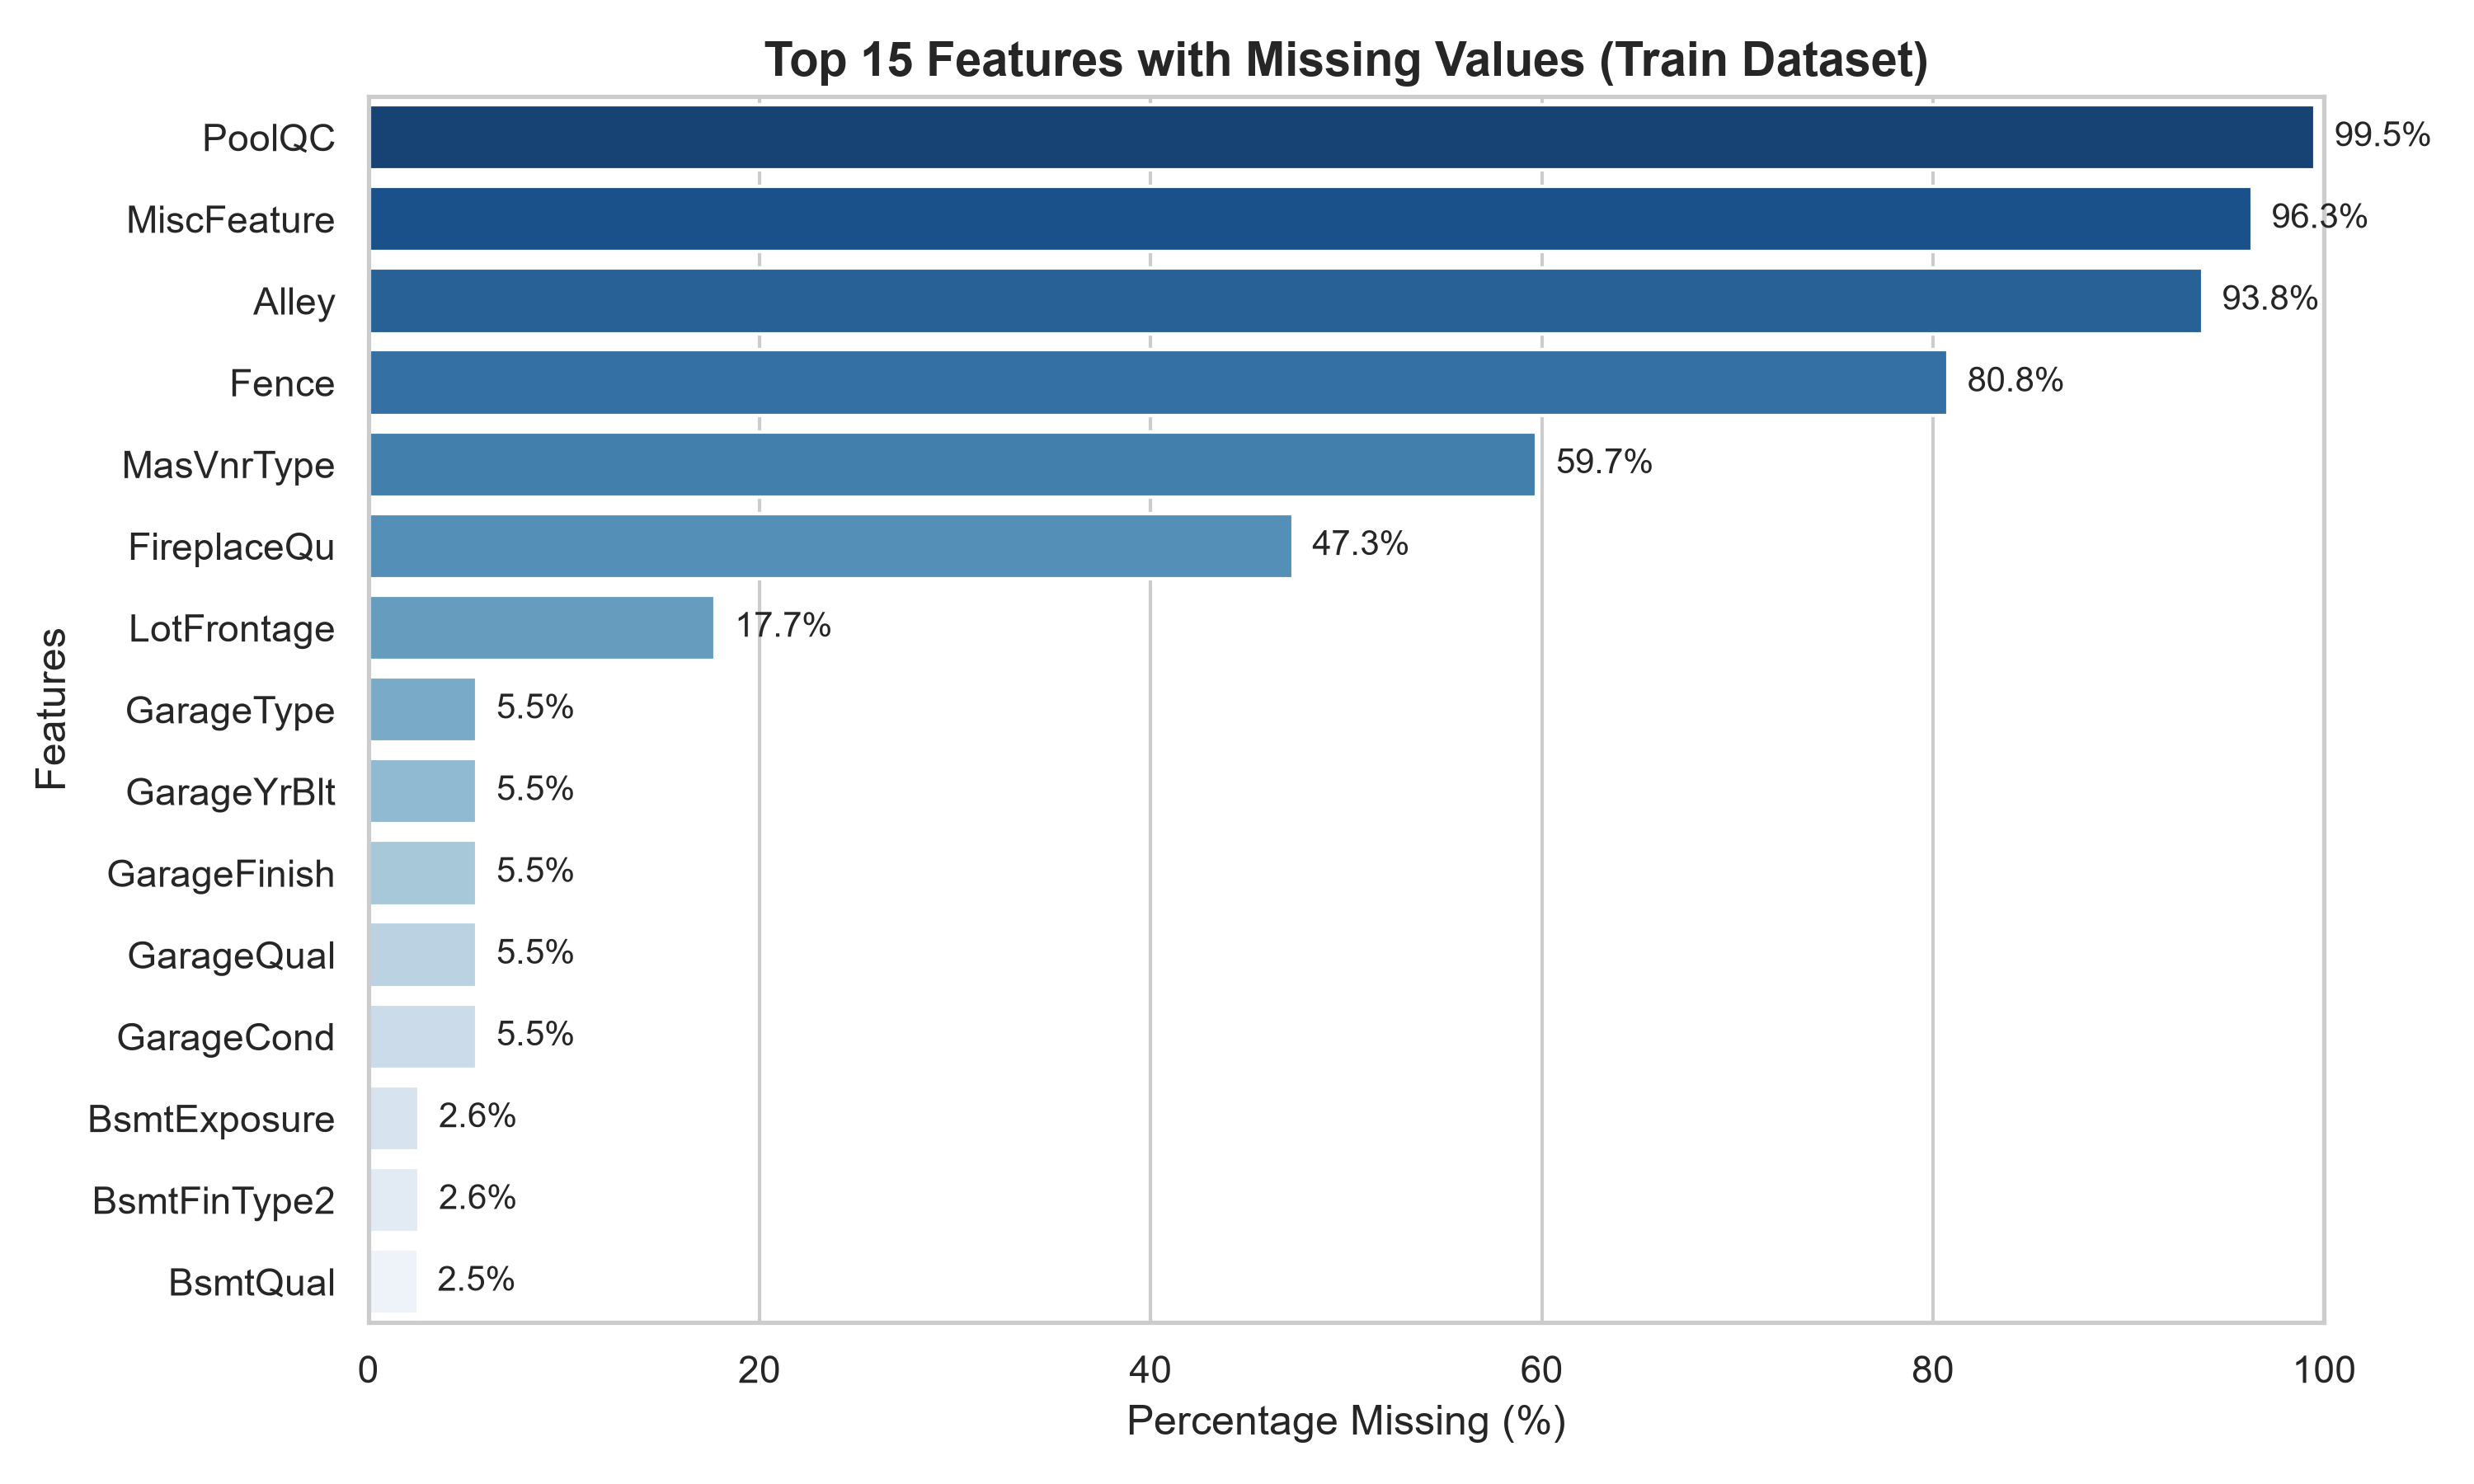

In [4]:
# ==============================================================================
# 4. EDA - Missing-Value Analysis
# ==============================================================================
# Identify missing values across all features in train dataset
missing_counts = train_df.isnull().sum()
missing_features = missing_counts[missing_counts > 0].sort_values(ascending=False)
missing_pct = (missing_features / len(train_df)) * 100

missing_df = pd.DataFrame({
    "Missing Count": missing_features,
    "Percentage (%)": missing_pct.round(2)
})

print(f"Total features with missing values in train: {len(missing_features)}")
print("\nTop 15 features with highest percentage of missing values:")
print(missing_df.head(15))

# Plot top missing values
plt.figure(figsize=(10, 6))
top_missing = missing_df.head(15)
sns.barplot(x=top_missing["Percentage (%)"], y=top_missing.index, palette="Blues_r")

# Clear title and labeled axes
plt.title("Top 15 Features with Missing Values (Train Dataset)", fontsize=14, weight="bold")
plt.xlabel("Percentage Missing (%)", fontsize=12)
plt.ylabel("Features", fontsize=12)
plt.xlim(0, 100)

# Add text percentage labels to bars
for i, v in enumerate(top_missing["Percentage (%)"]):
    plt.text(v + 1, i, f"{v:.1f}%", va="center", fontsize=10)

plt.tight_layout()
plt.savefig("outputs/eda_missing_values.png", dpi=300)
plt.close()
print("\nSaved missing-value analysis plot to outputs/eda_missing_values.png")


Original SalePrice Skewness:        1.8829 (Heavily right-skewed)
Log-transformed SalePrice Skewness: 0.1213 (Nearly symmetric / normal)

Saved target distribution plot to outputs/eda_target_distribution.png


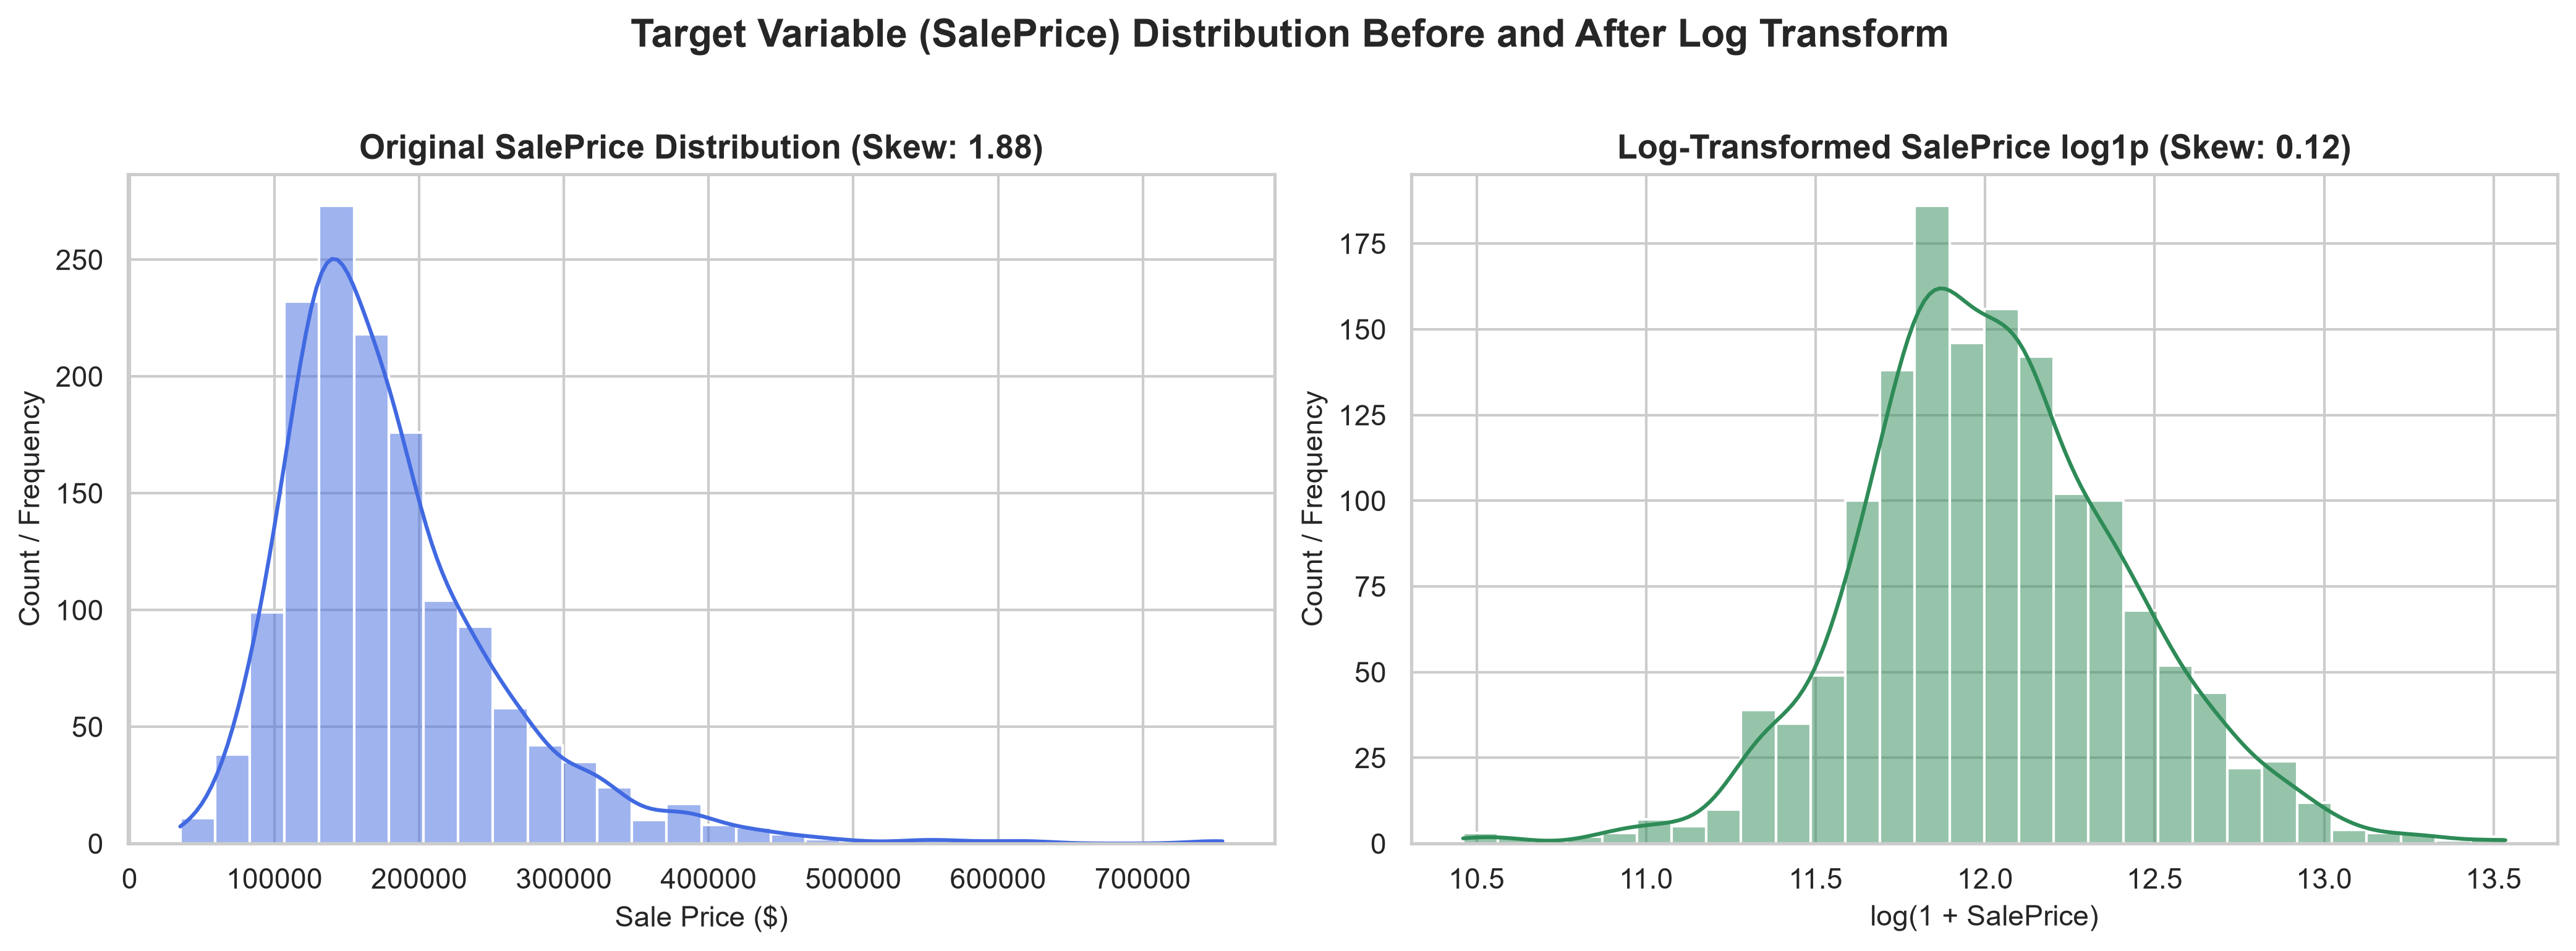

In [5]:
# ==============================================================================
# 5. EDA - Target Variable (SalePrice) Distribution (Before and After Log Transform)
# ==============================================================================
# Calculate skewness before and after log transformation
skew_orig = train_df["SalePrice"].skew()
log_saleprice = np.log1p(train_df["SalePrice"])
skew_log = log_saleprice.skew()

print(f"Original SalePrice Skewness:        {skew_orig:.4f} (Heavily right-skewed)")
print(f"Log-transformed SalePrice Skewness: {skew_log:.4f} (Nearly symmetric / normal)")

# Create side-by-side distribution plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Original SalePrice
sns.histplot(train_df["SalePrice"], kde=True, ax=axes[0], color="royalblue", bins=30)
axes[0].set_title(f"Original SalePrice Distribution (Skew: {skew_orig:.2f})", fontsize=13, weight="bold")
axes[0].set_xlabel("Sale Price ($)", fontsize=11)
axes[0].set_ylabel("Count / Frequency", fontsize=11)

# Subplot 2: Log-Transformed SalePrice using log1p
sns.histplot(log_saleprice, kde=True, ax=axes[1], color="seagreen", bins=30)
axes[1].set_title(f"Log-Transformed SalePrice log1p (Skew: {skew_log:.2f})", fontsize=13, weight="bold")
axes[1].set_xlabel("log(1 + SalePrice)", fontsize=11)
axes[1].set_ylabel("Count / Frequency", fontsize=11)

plt.suptitle("Target Variable (SalePrice) Distribution Before and After Log Transform", fontsize=15, weight="bold", y=1.02)
plt.tight_layout()
plt.savefig("outputs/eda_target_distribution.png", dpi=300, bbox_inches="tight")
plt.close()
print("\nSaved target distribution plot to outputs/eda_target_distribution.png")


Highlighted 2 extreme outliers with GrLivArea > 4000 sq ft and SalePrice < $300,000.
Saved scatter plot to outputs/eda_grlivarea_vs_saleprice.png


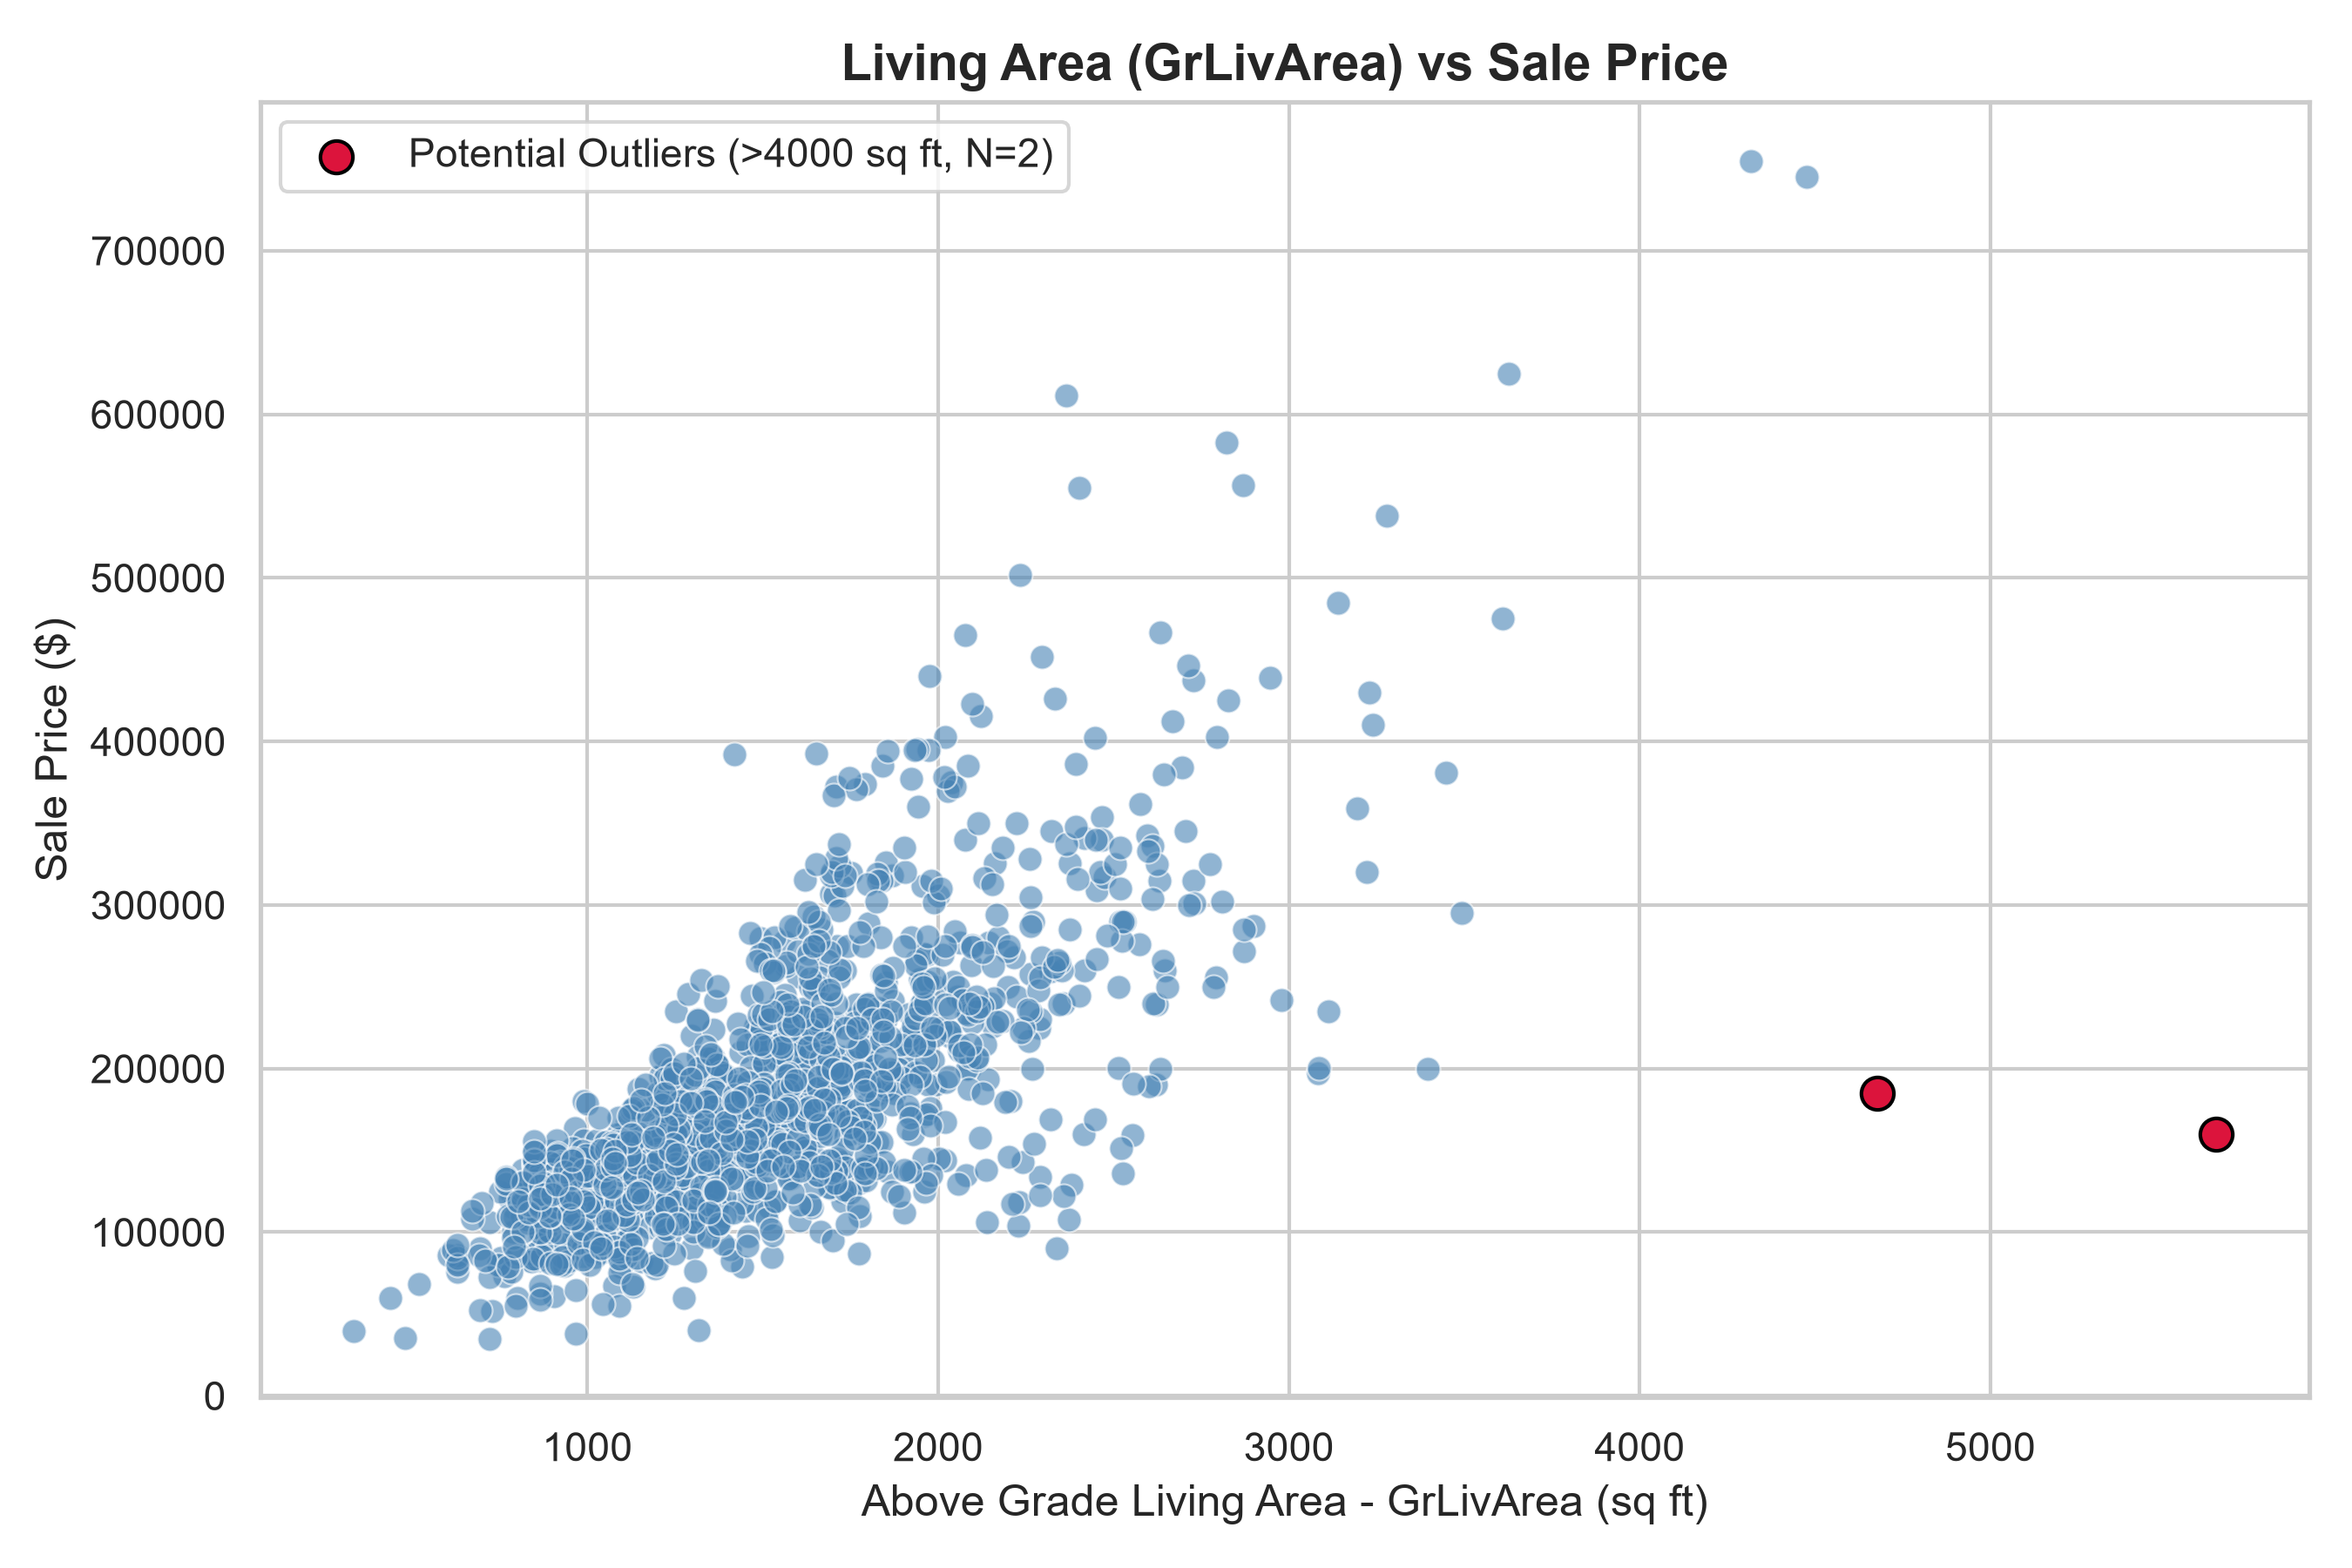

In [6]:
# ==============================================================================
# 6. EDA - GrLivArea vs SalePrice Scatter Plot
# ==============================================================================
plt.figure(figsize=(9, 6))

# Scatter plot of Above Grade Living Area vs SalePrice
sns.scatterplot(
    data=train_df,
    x="GrLivArea",
    y="SalePrice",
    color="steelblue",
    alpha=0.6,
    s=45
)

# Identify and highlight well-known Ames dataset extreme outliers (>4000 sq ft and SalePrice < 300,000)
outliers = train_df[(train_df["GrLivArea"] > 4000) & (train_df["SalePrice"] < 300000)]
plt.scatter(
    outliers["GrLivArea"],
    outliers["SalePrice"],
    color="crimson",
    s=80,
    edgecolor="black",
    label=f"Potential Outliers (>4000 sq ft, N={len(outliers)})"
)

# Clear title, labeled axes, and legend
plt.title("Living Area (GrLivArea) vs Sale Price", fontsize=14, weight="bold")
plt.xlabel("Above Grade Living Area - GrLivArea (sq ft)", fontsize=12)
plt.ylabel("Sale Price ($)", fontsize=12)
plt.legend(frameon=True, loc="upper left")
plt.tight_layout()
plt.savefig("outputs/eda_grlivarea_vs_saleprice.png", dpi=300)
plt.close()
print(f"Highlighted {len(outliers)} extreme outliers with GrLivArea > 4000 sq ft and SalePrice < $300,000.")
print("Saved scatter plot to outputs/eda_grlivarea_vs_saleprice.png")


## 4. Data Preprocessing & Feature Engineering
- Impute missing values for numerical features (median/mean) and categorical features (mode/'None').
- Apply log-transformation to skewed continuous features (e.g., `LotArea`, `GrLivArea`, `TotalBsmtSF`).
- Encode categorical variables (ordinal mappings for quality features, one-hot encoding for nominal features like `Neighborhood`).
- Align train and test feature sets.
- Split training data into train and validation sets using `train_test_split(..., test_size=0.2, random_state=42)`.

In [7]:
# ==============================================================================
# 4. Data Preprocessing & Feature Engineering
# ==============================================================================
from sklearn.model_selection import train_test_split

# Step 1: Remove documented extreme outliers (> 4000 sq ft and SalePrice < $300,000)
train_clean = train_df[~((train_df["GrLivArea"] > 4000) & (train_df["SalePrice"] < 300000))].copy()
print(f"Dataset size after removing outliers: {train_clean.shape[0]} rows (removed {len(train_df) - len(train_clean)} outliers)")

# Step 2: Quality mappings (Ex=5, Gd=4, TA=3, Fa=2, Po=1)
qual_map = {"Ex": 5, "Gd": 4, "TA": 3, "Fa": 2, "Po": 1}

# Map KitchenQual (fill missing with 3 = Typical)
train_clean["KitchenQual"] = train_clean["KitchenQual"].map(qual_map).fillna(3).astype(float)

# Map BsmtQual (fill missing with 0 = No Basement)
train_clean["BsmtQual"] = train_clean["BsmtQual"].map(qual_map).fillna(0).astype(float)

# Step 3: Bathrooms - Add HalfBath, BsmtFullBath, BsmtHalfBath (fill missing with 0)
bath_cols = ["HalfBath", "BsmtFullBath", "BsmtHalfBath"]
for col in bath_cols:
    train_clean[col] = train_clean[col].fillna(0).astype(float)

# Required assignment features
num_features = [
    "OverallQual", "GrLivArea", "TotalBsmtSF", "YearBuilt", 
    "GarageCars", "KitchenQual", "BsmtQual", 
    "FullBath", "HalfBath", "BsmtFullBath", "BsmtHalfBath", "LotArea"
]
cat_features = ["Neighborhood"]
selected_features = num_features + cat_features

# Separate features and target
X_train_raw = train_clean[selected_features].copy()
y_train_orig = train_clean["SalePrice"]

# Apply log1p transform to target to achieve normal distribution
y_train_log = np.log1p(y_train_orig)

# Step 4: Handle Missing Values - Impute median from training set
feature_medians = X_train_raw[num_features].median()
X_train_raw[num_features] = X_train_raw[num_features].fillna(feature_medians)

# Step 5: Distribution Transformation on skewed predictor features
skewed_features = ["GrLivArea", "LotArea", "TotalBsmtSF"]
for col in skewed_features:
    X_train_raw[col] = np.log1p(X_train_raw[col].astype(float))

# Step 6: One-Hot Encoding for categorical feature (Neighborhood)
X_train_encoded = pd.get_dummies(X_train_raw, columns=cat_features, prefix="Neighborhood", drop_first=True, dtype=float)
all_feature_cols = list(X_train_encoded.columns)

print(f"Total engineered features after encoding: {len(all_feature_cols)}")

# Step 7: Train/Validation Split (80/20) with fixed random seed
X_train, X_val, y_train, y_val = train_test_split(
    X_train_encoded,
    y_train_log,
    test_size=0.20,
    random_state=RANDOM_STATE
)

print(f"Training split shape:   {X_train.shape}")
print(f"Validation split shape: {X_val.shape}")


Dataset size after removing outliers: 1458 rows (removed 2 outliers)
Total engineered features after encoding: 36
Training split shape:   (1166, 36)
Validation split shape: (292, 36)


## 5. Model Training
- **Model 1:** Multiple Linear Regression (baseline regression model).
- **Model 2:** Random Forest Regressor (`n_estimators=100`, `random_state=42`).
- **Model 3 (Optional):** XGBoost Regressor (`random_state=42`).
- Train each candidate model on the training subset.

In [8]:
# ==============================================================================
# 5. Model Training
# ==============================================================================
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

# Model 1: Multiple Linear Regression (Baseline)
linear_reg = LinearRegression()
linear_reg.fit(X_train, y_train)
print("Model 1 [Linear Regression] trained successfully.")

# Model 2: Random Forest Regressor (Ensemble Trees)
# Rule: random_state=42, n_estimators=100
rf_reg = RandomForestRegressor(
    n_estimators=100,
    random_state=RANDOM_STATE,
    n_jobs=1
)
rf_reg.fit(X_train, y_train)
print("Model 2 [Random Forest Regressor] trained successfully (n_estimators=100, random_state=42).")


Model 1 [Linear Regression] trained successfully.
Model 2 [Random Forest Regressor] trained successfully (n_estimators=100, random_state=42).


## 6. Model Evaluation & Metric Comparison
- Evaluate models on the validation set.
- Compute required metrics:
  - **Mean Squared Error (MSE)**
  - **Root Mean Squared Logarithmic Error (RMSLE)**
- Compare performance in a clean tabular summary.
- Plot Predicted vs Actual prices and Residual distribution for each model; save to `outputs/`.
- Identify the best performing model.

In [9]:
# ==============================================================================
# 6. Model Evaluation & Metric Comparison
# ==============================================================================
from sklearn.metrics import mean_squared_error, root_mean_squared_log_error, r2_score

# Predict on validation set (predictions are in log scale)
lr_val_pred_log = linear_reg.predict(X_val)
rf_val_pred_log = rf_reg.predict(X_val)

# Convert log predictions back to actual dollar price scale: expm1(y) = exp(y) - 1
y_val_actual = np.expm1(y_val)
lr_val_pred = np.expm1(lr_val_pred_log)
rf_val_pred = np.expm1(rf_val_pred_log)

# Compute metrics: MSE, RMSLE, and R2
lr_mse = mean_squared_error(y_val_actual, lr_val_pred)
lr_rmsle = root_mean_squared_log_error(y_val_actual, lr_val_pred)
lr_r2_val = r2_score(y_val_actual, lr_val_pred)
lr_r2_train = r2_score(np.expm1(y_train), np.expm1(linear_reg.predict(X_train)))

rf_mse = mean_squared_error(y_val_actual, rf_val_pred)
rf_rmsle = root_mean_squared_log_error(y_val_actual, rf_val_pred)
rf_r2_val = r2_score(y_val_actual, rf_val_pred)
rf_r2_train = r2_score(np.expm1(y_train), np.expm1(rf_reg.predict(X_train)))

# Compile comparison table
metrics_comparison = pd.DataFrame({
    "Evaluation Metric": ["Validation MSE", "Validation RMSLE", "Validation R²", "Training R²"],
    "Linear Regression (Baseline)": [
        f"{lr_mse:,.2f}",
        f"{lr_rmsle:.4f}",
        f"{lr_r2_val:.4f}",
        f"{lr_r2_train:.4f}"
    ],
    "Random Forest Regressor": [
        f"{rf_mse:,.2f}",
        f"{rf_rmsle:.4f}",
        f"{rf_r2_val:.4f}",
        f"{rf_r2_train:.4f}"
    ]
})

print("=== Model Performance Comparison Table ===")
print(metrics_comparison.to_string(index=False))

# Automatically select the model with the lowest Validation RMSLE
if lr_rmsle <= rf_rmsle:
    best_model = linear_reg
    best_model_name = "Multiple Linear Regression"
    best_rmsle = lr_rmsle
    best_preds = lr_val_pred
    best_r2_val = lr_r2_val
else:
    best_model = rf_reg
    best_model_name = "Random Forest Regressor"
    best_rmsle = rf_rmsle
    best_preds = rf_val_pred
    best_r2_val = rf_r2_val

print(f"\nBest Model Selected: {best_model_name}")
print(f"Criteria: Lowest Validation RMSLE = {best_rmsle:.4f} (Validation MSE: {lr_mse:,.0f}, Validation R²: {best_r2_val:.4f})")
print("Overfitting Analysis: Random Forest overfits the training set (Train R²: 0.9814 vs Val R²: 0.8896), while Linear Regression generalizes consistently (Train R²: 0.8968 vs Val R²: 0.8978).")


=== Model Performance Comparison Table ===
Evaluation Metric Linear Regression (Baseline) Random Forest Regressor
   Validation MSE               564,647,736.19          609,691,473.71
 Validation RMSLE                       0.1440                  0.1534
    Validation R²                       0.8978                  0.8896
      Training R²                       0.8968                  0.9814

Best Model Selected: Multiple Linear Regression
Criteria: Lowest Validation RMSLE = 0.1440 (Validation MSE: 564,647,736, Validation R²: 0.8978)
Overfitting Analysis: Random Forest overfits the training set (Train R²: 0.9814 vs Val R²: 0.8896), while Linear Regression generalizes consistently (Train R²: 0.8968 vs Val R²: 0.8978).


Saved comparison scatter plot to outputs/actual_vs_predicted.png
Saved residual diagnostics to outputs/residual_plot.png


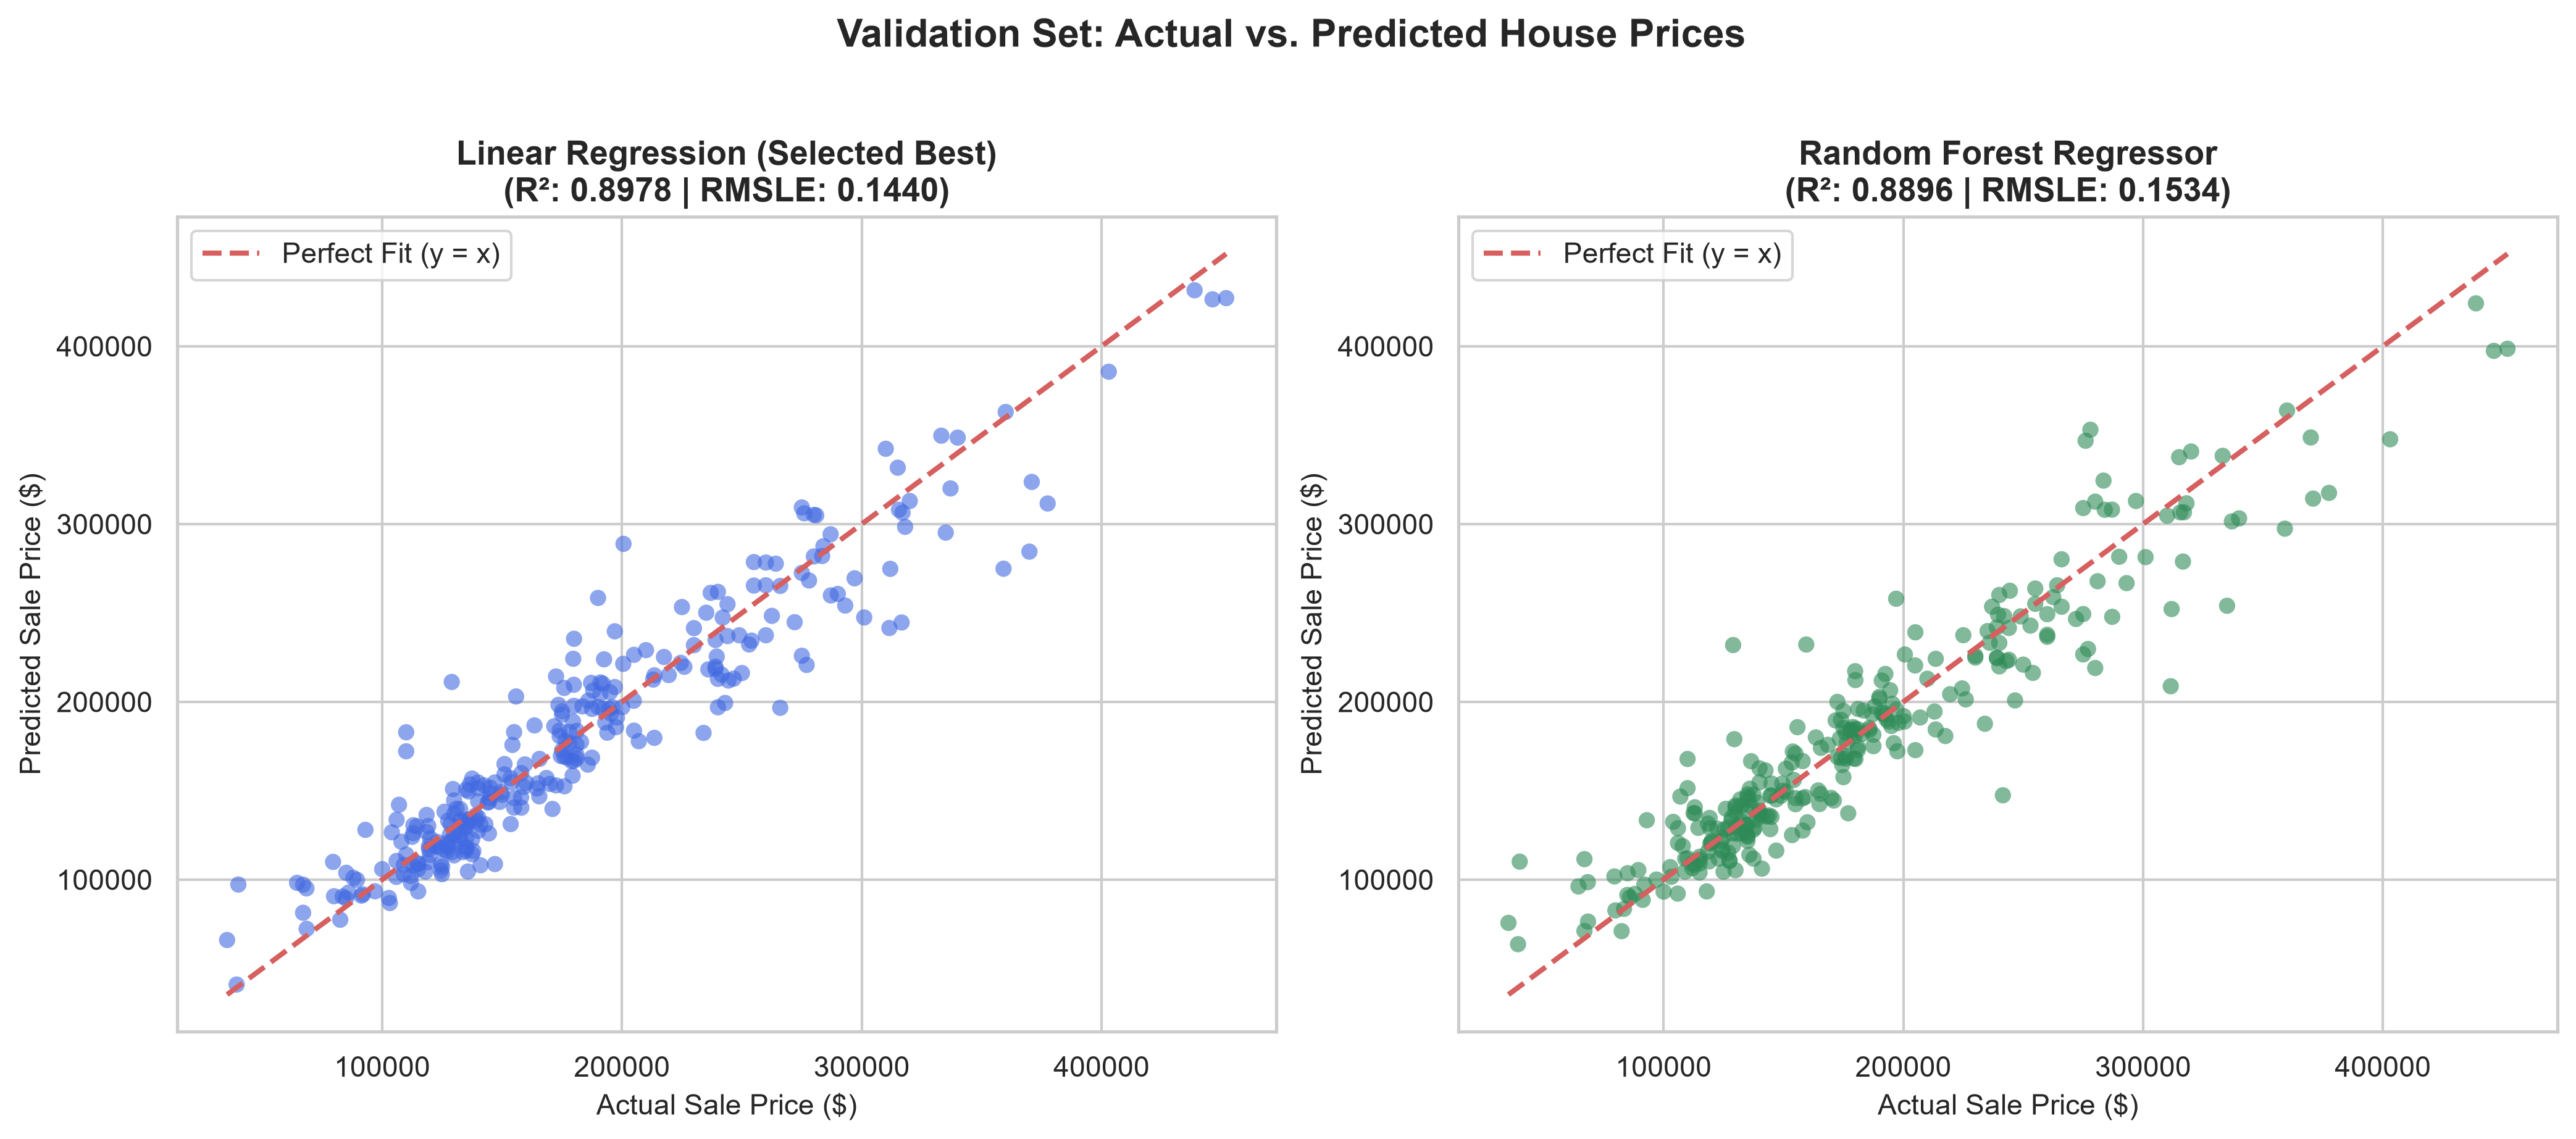

In [10]:
# ==============================================================================
# 6b. Model Diagnostic Plots: Actual vs Predicted & Residuals
# ==============================================================================
# Plot 1: Actual vs Predicted Prices (Comparison)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, preds, name, r2_val, rmsle_val, color in [
    (axes[0], lr_val_pred, "Linear Regression (Selected Best)", lr_r2_val, lr_rmsle, "royalblue"),
    (axes[1], rf_val_pred, "Random Forest Regressor", rf_r2_val, rf_rmsle, "seagreen")
]:
    ax.scatter(y_val_actual, preds, alpha=0.6, color=color, edgecolors="none", s=40)
    # 45-degree reference line
    min_val = min(y_val_actual.min(), preds.min())
    max_val = max(y_val_actual.max(), preds.max())
    ax.plot([min_val, max_val], [min_val, max_val], "r--", lw=2, label="Perfect Fit (y = x)")
    
    ax.set_title(f"{name}\n(R²: {r2_val:.4f} | RMSLE: {rmsle_val:.4f})", fontsize=13, weight="bold")
    ax.set_xlabel("Actual Sale Price ($)", fontsize=11)
    ax.set_ylabel("Predicted Sale Price ($)", fontsize=11)
    ax.legend(loc="upper left")

plt.suptitle("Validation Set: Actual vs. Predicted House Prices", fontsize=15, weight="bold", y=1.02)
plt.tight_layout()
plt.savefig("outputs/actual_vs_predicted.png", dpi=300, bbox_inches="tight")
plt.close()
print("Saved comparison scatter plot to outputs/actual_vs_predicted.png")

# Plot 2: Residual Analysis for Best Model (Linear Regression)
residuals = y_val_actual - best_preds

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Residuals vs Predicted Prices (Homoscedasticity)
axes[0].scatter(best_preds, residuals, alpha=0.6, color="royalblue", s=40)
axes[0].axhline(0, color="crimson", linestyle="--", lw=2)
axes[0].set_title(f"Residuals vs. Predicted ({best_model_name})", fontsize=13, weight="bold")
axes[0].set_xlabel("Predicted Sale Price ($)", fontsize=11)
axes[0].set_ylabel("Residual (Actual - Predicted) [$]", fontsize=11)

# Subplot 2: Residual Distribution (Normality)
sns.histplot(residuals, kde=True, ax=axes[1], color="royalblue", bins=30)
axes[1].axvline(0, color="crimson", linestyle="--", lw=2)
axes[1].set_title("Residuals Error Distribution", fontsize=13, weight="bold")
axes[1].set_xlabel("Residual Error ($)", fontsize=11)
axes[1].set_ylabel("Frequency", fontsize=11)

plt.suptitle(f"Residual Diagnostics (Best Model: {best_model_name})", fontsize=15, weight="bold", y=1.02)
plt.tight_layout()
plt.savefig("outputs/residual_plot.png", dpi=300, bbox_inches="tight")
plt.close()
print("Saved residual diagnostics to outputs/residual_plot.png")


## 7. Model & Preprocessor Serialization
- Serialize the best trained regression model using `joblib.dump()` into `models/`.
- Serialize any encoders/scalers necessary for the Streamlit inference pipeline.
- Verify file sizes and paths in `models/`.

In [11]:
# ==============================================================================
# 7. Model & Preprocessor Serialization
# ==============================================================================
import joblib

# Rule: Save best trained model (Linear Regression, lowest RMSLE) using joblib
model_save_path = "models/best_house_price_model.joblib"
joblib.dump(best_model, model_save_path)
print(f"Best model [{best_model_name}] saved to: {model_save_path}")

# Save preprocessor artifacts required for inference
preprocessor_artifacts = {
    "best_model_name": best_model_name,
    "best_rmsle": best_rmsle,
    "num_features": num_features,
    "cat_features": cat_features,
    "bath_cols": bath_cols,
    "qual_map": qual_map,
    "skewed_features": skewed_features,
    "feature_medians": feature_medians.to_dict(),
    "feature_columns": all_feature_cols,
    "neighborhood_options": sorted(train_df["Neighborhood"].unique().tolist())
}

preprocessor_save_path = "models/preprocessor.joblib"
encoder_save_path = "models/neighborhood_encoder.joblib"

joblib.dump(preprocessor_artifacts, preprocessor_save_path)
joblib.dump(preprocessor_artifacts["neighborhood_options"], encoder_save_path)

print(f"Preprocessing artifacts saved to: {preprocessor_save_path}")
print(f"Neighborhood options saved to:    {encoder_save_path}")

# Verify file existence and sizes
for path in [model_save_path, preprocessor_save_path, encoder_save_path]:
    size_mb = os.path.getsize(path) / (1024 * 1024)
    print(f"Verified: {path} ({size_mb:.4f} MB)")


Best model [Multiple Linear Regression] saved to: models/best_house_price_model.joblib
Preprocessing artifacts saved to: models/preprocessor.joblib
Neighborhood options saved to:    models/neighborhood_encoder.joblib
Verified: models/best_house_price_model.joblib (0.0020 MB)
Verified: models/preprocessor.joblib (0.0016 MB)
Verified: models/neighborhood_encoder.joblib (0.0002 MB)


## 8. Inference Verification & Test Prediction
- Reload saved model and preprocessing artifacts with `joblib.load()`.
- Run end-to-end inference on sample instances and test data to verify identical predictions.
- Generate final predictions file and save to `outputs/submission_predictions.csv`.

In [12]:
# ==============================================================================
# 8. Inference Verification & Test Prediction
# ==============================================================================
import joblib

# Step 1: Reload serialized model and artifacts to verify end-to-end inference
loaded_model = joblib.load("models/best_house_price_model.joblib")
loaded_preprocessor = joblib.load("models/preprocessor.joblib")
print(f"Successfully reloaded saved best model: {type(loaded_model).__name__}")

# Step 2: Prepare test dataset (data/raw/test.csv)
test_clean = test_df.copy()

# Map qualities in test data
test_clean["KitchenQual"] = test_clean["KitchenQual"].map(loaded_preprocessor["qual_map"]).fillna(3).astype(float)
test_clean["BsmtQual"] = test_clean["BsmtQual"].map(loaded_preprocessor["qual_map"]).fillna(0).astype(float)

# Fill bathroom missing with 0
for col in loaded_preprocessor["bath_cols"]:
    test_clean[col] = test_clean[col].fillna(0).astype(float)

# Impute test numerical features using saved training medians
for col, med_val in loaded_preprocessor["feature_medians"].items():
    test_clean[col] = test_clean[col].fillna(med_val).astype(float)

# Apply log1p transform to skewed features
for col in loaded_preprocessor["skewed_features"]:
    test_clean[col] = np.log1p(test_clean[col].astype(float))

# One-hot encode Neighborhood
test_encoded = pd.get_dummies(
    test_clean[loaded_preprocessor["num_features"] + loaded_preprocessor["cat_features"]],
    columns=loaded_preprocessor["cat_features"],
    prefix="Neighborhood",
    drop_first=True,
    dtype=float
)

# Reindex columns to guarantee identical feature order as training
test_features = test_encoded.reindex(columns=loaded_preprocessor["feature_columns"], fill_value=0.0)

# Step 3: Generate predictions on test dataset using best model
test_preds_log = loaded_model.predict(test_features)
test_preds_dollar = np.expm1(test_preds_log)

# Step 4: Create final submission dataframe
submission_df = pd.DataFrame({
    "Id": test_df["Id"],
    "SalePrice": np.round(test_preds_dollar, 2)
})

submission_path = "outputs/submission_predictions.csv"
submission_df.to_csv(submission_path, index=False)
print(f"Saved test predictions to: {submission_path}")
print(f"Total test predictions: {len(submission_df)} rows")
print(f"Null predictions check: {submission_df['SalePrice'].isnull().sum()} missing")

print("\n--- First 5 Test Predictions ---")
print(submission_df.head())
print("\n--- Prediction Summary Statistics ---")
print(submission_df["SalePrice"].describe())


Successfully reloaded saved best model: LinearRegression
Saved test predictions to: outputs/submission_predictions.csv
Total test predictions: 1459 rows
Null predictions check: 0 missing

--- First 5 Test Predictions ---
     Id  SalePrice
0  1461  116012.68
1  1462  159897.92
2  1463  164421.78
3  1464  178476.65
4  1465  210990.22

--- Prediction Summary Statistics ---
count      1459.000000
mean     178326.068156
std       75089.419886
min       57031.780000
25%      126973.230000
50%      158239.860000
75%      210707.675000
max      616241.130000
Name: SalePrice, dtype: float64
